<a href="https://colab.research.google.com/github/Endoefa/ovo/blob/main/Tutorial_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import libraries, packages and modules

In [10]:
from skimage.feature import local_binary_pattern   # import the local_binary_pattern() function from skimage library
from skimage import data              # for more information about the skimage please visit https://scikit-image.org/
from skimage.color import label2rgb        # function importing. see comments below
import matplotlib.pyplot as plt         # ...
import numpy as np               # ...

# Set parameters for LBP
For more information, please watch the lecture recordings or find the definitions in this paper https://www.researchgate.net/publication/331541161_Circular_Derivative_Local_Binary_Pattern_Feature_Description_for_Facial_Expression_Recognition

In [11]:
# 设置 LBP 参数；详细定义可参考课程录屏或上方论文
radius = 3  # 设置 LBP 圆形邻域的半径
n_points = 8 * radius  # 设置圆形邻域内采样点的数量；这里半径为 3，因此采样 24 个点

# Define functions for later use
The following codes defines a function which can mark the area with certain features
下面的函数可以根据指定的 LBP 特征标签，在原图上标出对应区域。

In [12]:
def overlay_labels(image, lbp, labels):
    # 对每个指定标签分别比较，得到一组布尔矩阵；True 表示该位置的 LBP 值等于对应标签
    # 将这些布尔矩阵按逻辑“或”合并，得到包含所有目标标签区域的掩膜
    mask = np.logical_or.reduce([lbp == each for each in labels])  #lbp == each for each in labels是在lbp矩阵的每一个位置和 labels里包含的
    #                                                              每一个label比是否相等，相等本次loop对应值则为true，有几个label就会生成几个布尔矩阵
    #logical_or 是逻辑“或”：只要几个值里至少有一个是 True，结果就是 True 因此最终得到的是：LBP 值等于 labels 中任意一个编号的位置为 True，其余位置为 False


    # 可取消下一行注释，查看每个标签分别对应的布尔矩阵
    print([lbp == each for each in labels])

    # 将掩膜以半透明方式叠加到原图上；bg_label=0 表示标签 0 作为背景
    return label2rgb(mask, image=image, bg_label=0, alpha=0.5) #bg_label=0 指的是把 False 的位置当作背景；`True` 的位置就是掩膜选中的区域。

The function below is defined to color all selected bars red, it intake the bar chart object and the indexes of bars which you want to color

In [13]:
def highlight_bars(bars, indexes):
    # 逐个取出指定索引对应的柱子，并将填充颜色设为红色
    for i in indexes:
        bars[i].set_facecolor('r')

This following function is defined to draw a histogram of a LBP feature map

In [14]:
def hist(ax, lbp):   #ax：要在哪个子图上画直方图。
    # LBP 特征值是离散整数；最大特征值加 1，作为直方图的柱子数量
    n_bins = int(lbp.max() + 1)

    # 将二维特征图展平成一维数组后绘制直方图
    # density=True 表示纵轴显示归一化后的比例密度
    return ax.hist(   #ax.hist(...) 表示在 ax 对应的子图上画直方图。
        lbp.ravel(),   #要统计的一维 LBP 编码数据。
        density=True,
        bins=n_bins,  #把横轴分成 n_bins 个区间，也就是安排多少根柱子。
        range=(0, n_bins),
        facecolor='0.5'
    )

# Read an image and calculate the LPB feature
Start to study the code for this week from this chapter

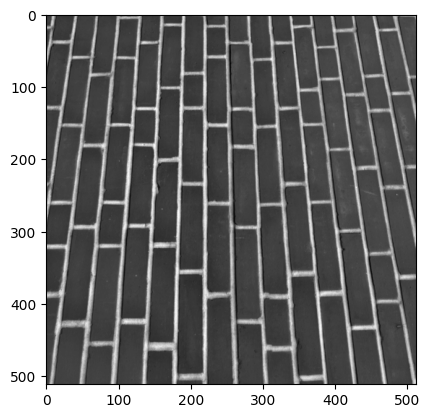

In [15]:
image = data.brick()  # 从 scikit-image 的示例数据中读取砖墙图像
plt.imshow(image, cmap='gray')  # 以灰度色图显示原始图像

# 计算图像的 LBP 特征图：使用 n_points 个邻域采样点、半径 radius 和 uniform 模式
lbp = local_binary_pattern(image, n_points, radius, 'uniform')  #local_binary_pattern 是 scikit-image 里的一个函数，用来计算图像的局部二值模式（LBP）特
#如果把 24 个采样点都按普通的 0/1 编码，理论上会有 \(2^{24}\) 种组合。但这段代码还指定了 'uniform' 模式：
#它把编码中“0 和 1 来回切换不超过两次”的模式单独归类，其余复杂模式合并成一类。

# Show visualised LPB feature显示并分析 LBP 特征

[array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False,  True, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]], shape=(512, 512)), array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]], shape=(512, 512)), array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False

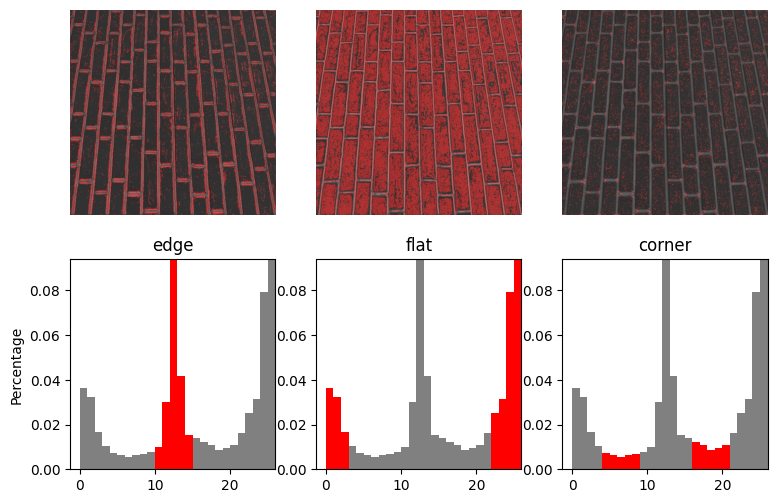

In [16]:
# 创建 2 行 3 列的子图：上排显示不同类别的图像区域，下排显示对应直方图
fig, (ax_img, ax_hist) = plt.subplots(nrows=2, ncols=3, figsize=(9, 6))
plt.gray()  # 将默认色图设为灰度

# 三类 LBP 特征的显示标题
titles = ('edge', 'flat', 'corner')

# 根据半径设置分类范围的宽度
w = width = radius - 1

# 选出被视为边缘特征的 LBP 标签
edge_labels = range(n_points // 2 - w, n_points // 2 + w + 1)

# 选出被视为平坦区域特征的 LBP 标签；标签范围可能跨越编码序列首尾，因此分两段表示
flat_labels = list(range(0, w + 1)) + list(range(n_points - w, n_points + 2))

# 计算直方图中约 1/4 和 3/4 位置，用于选出角点特征标签
i_14 = n_points // 4
i_34 = 3 * (n_points // 4)
corner_labels = (
    list(range(i_14 - w, i_14 + w + 1)) +
    list(range(i_34 - w, i_34 + w + 1))
)

# 将三类特征对应的标签集合放在一起，便于后续循环处理
label_sets = (edge_labels, flat_labels, corner_labels)

# 依次在上排三个子图中叠加显示边缘、平坦区域和角点对应的位置
for ax, labels in zip(ax_img, label_sets):
    ax.imshow(overlay_labels(image, lbp, labels))

# 依次绘制三类特征的直方图，并将对应标签的柱子标成红色
for ax, labels, name in zip(ax_hist, label_sets, titles):
    counts, _, bars = hist(ax, lbp)  # 绘制 LBP 直方图，保存柱高和柱状图对象
    highlight_bars(bars, labels)  # 将当前类别对应的柱子标红

    # 调整纵轴上限，避免最高柱超出显示范围；counts[:-1] 排除最后一个额外统计项
    ax.set_ylim(top=np.max(counts[:-1]))

    # 将横轴范围限制到 LBP 标签范围附近
    ax.set_xlim(right=n_points + 2)
    ax.set_title(name)  # 设置当前直方图标题

# 给下排第一个直方图添加纵轴标签
ax_hist[0].set_ylabel('Percentage')

# 隐藏上排图像的坐标轴刻度和边框
for ax in ax_img:
    ax.axis('off')

这段代码按 LBP 编码值，把局部纹理分成三类。当前参数是 `radius = 3`、`n_points = 24`，所以 `w = radius - 1 = 2`。

| 类别 | 代码选取的 LBP 标签 | 大致对应的局部纹理 |
|---|---:|---|
| 平坦区域 `flat` | `0–2` 和 `22–25` | 邻域亮度变化较少，局部比较平坦 |
| 边缘 `edge` | `10–14` | 亮暗大致沿一个方向分布，形成边缘 |
| 角点 `corner` | `4–8` 和 `16–20` | 亮暗在多个方向变化，呈现角点或类似结构 |

需要注意：这是示例代码根据 `uniform` LBP 编码范围划分的**近似类别**。代码是按标签区间选择并显示，不会进一步判断每个位置在原图中是否真的是边缘、平坦区域或角点。

最后的柱状图是 **LBP 标签的分布直方图**：

- **横轴**：LBP 编码标签（例如 0、1、2……）
- **纵轴**：每个标签在整张图的 LBP 特征图中所占的比例。因为 `hist()` 里设了 `density=True`，显示的是归一化后的分布，不是像素个数。
- **红色柱子**：当前正在展示的那一类标签，比如 `edge_labels`、`flat_labels` 或 `corner_labels`。

它回答的是：**这张砖墙图里，各种局部纹理编码出现得多不多？**上排的图则把对应标签在原图中的位置标出来。柱状图不是在画砖块数量，也不是直接识别出多少个角点或边缘。

182205


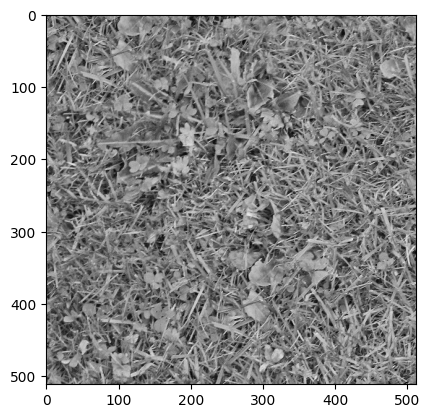

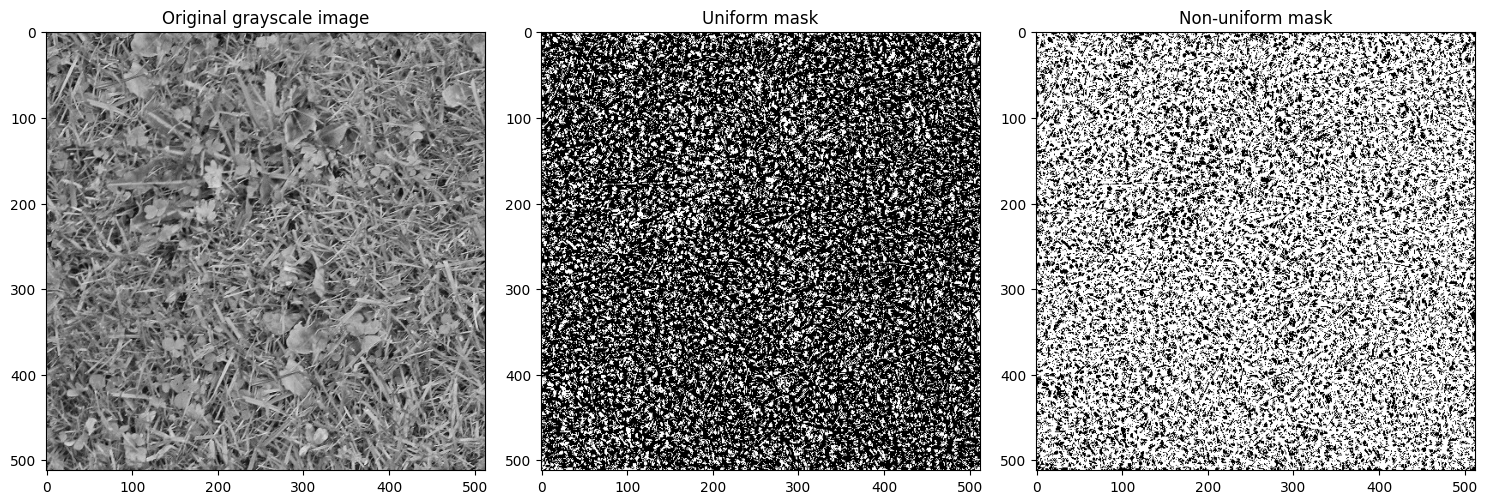

In [24]:
image = data.grass()
plt.imshow(image, cmap='gray')
radius = 5
n_points = 8 * radius

lbp = local_binary_pattern(image, n_points, radius, method='uniform')

uniform_mask = lbp != n_points + 1
non_uniform_mask = lbp == n_points + 1

non_uniform_count = np.count_nonzero(non_uniform_mask)
print(non_uniform_count)


fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(image, cmap='gray')
ax[0].set_title("Original grayscale image")

ax[1].imshow(uniform_mask, cmap='gray')
ax[1].set_title("Uniform mask")

ax[2].imshow(non_uniform_mask, cmap='gray')
ax[2].set_title("Non-uniform mask")

plt.tight_layout()
plt.show()

508


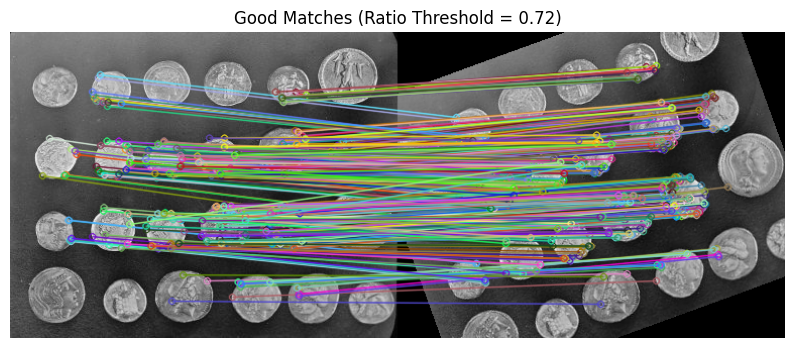

In [36]:
#Q2
from scipy.ndimage import rotate
import skimage.data
import cv2

# 1. Set the threshold value
ratio_threshold_q2 = 0.72

# 2. Obtain the coins image from the skimage.data (See Unit 4)
img1_q2 = skimage.data.coins()

# 3. Rotate the image using the rotate function (rotate(IMAGE, angle=ANGLE, reshape=False))
img2_q2 = rotate (img1_q2, angle=20, reshape=False) # Rotate by 20 degrees

# 4. Initialise ORB detector and find keypoints/descriptors
orb = cv2.ORB_create(nfeatures=1000)

# 5. Find the ORB keypoints for both images
keypoints1, descriptors1 = orb.detectAndCompute(img1_q2, None)
keypoints2, descriptors2 = orb.detectAndCompute(img2_q2, None)

# 6. Initialise Brute-Force Matcher
bf_matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)

# 7. Find the 2 best matches for each descriptor (k=2)
matches = bf_matcher.knnMatch(descriptors1, descriptors2, k=2)

# 8. Apply Lowe's ratio test to filter for good matches
good_matches = []

# Matches have two elements accessible using a loop:
for m, n in matches:
    # Assign the good matches based on distance
    if m.distance < ratio_threshold_q2 * n.distance:
        # Add m to the good_matches list
        good_matches.append(m)

# Find the number of good matches for your answer
answer_q2 = len(good_matches)
print(answer_q2)

# 9. Visualize the matches
matched_image = cv2.drawMatches(
    img1_q2, keypoints1, # missing: Image1, Image1 keypoints
    img2_q2, keypoints2, # missing: Image2, Image2 keypoints
    good_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Uncomment the resize for better display if needed
# matched_image_resized = cv2.resize(matched_image, (0, 0), fx=0.7, fy=0.7)

# Show the image
plt.figure(figsize=(10, 6))
plt.imshow(matched_image, cmap='gray')
# Display the image
plt.title(f'Good Matches (Ratio Threshold = {ratio_threshold_q2:.2f})')
plt.axis('off')
plt.show()

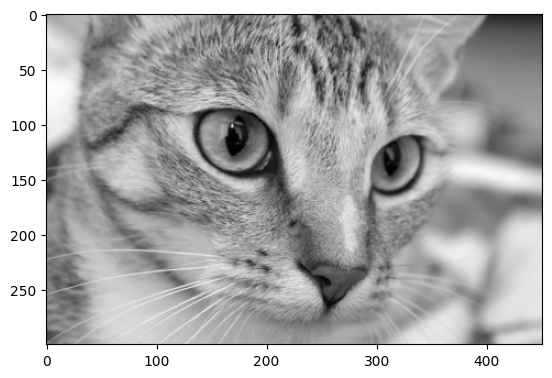

0.087


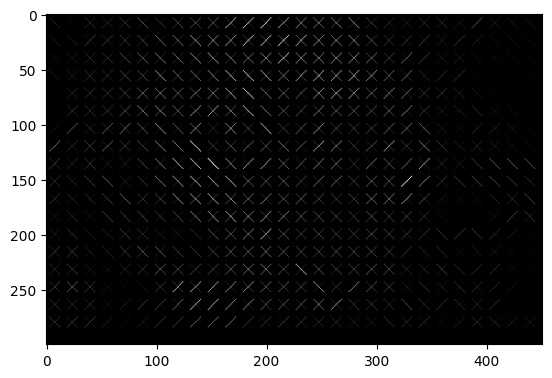

In [54]:
import skimage.feature

image = data.chelsea()
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
plt.figure()
plt.imshow(gray, cmap='gray')
plt.show()

hog_vals = skimage.feature.hog (
    gray,
    orientations=2,
    pixels_per_cell=(16, 16),
    cells_per_block=(2, 2),
    visualize=True,
)

hog_image = hog_vals[1]
std = np.std(hog_vals[0]).round(3)
print (std)
plt.imshow(hog_image, cmap='gray')

